# Bagian E — Temporal Association Analysis

Notebook ini menggunakan kembali `data/processed/tx_author_year_based.pkl` yang dibuat Task 3, lalu membagi transaksi ke periode untuk mining dan perbandingan rules. Karena pickle transaksi menyimpan `list[set[str]]` tanpa tahun, Task 3 juga menyimpan sidecar `tx_author_year_years.pkl` dengan urutan tahun yang sejajar. Notebook ini memuat kedua pickle tersebut—tidak membaca parquet atau membangun ulang transaksi. Hasil disimpan di `data/results/`, dan grafik memakai awalan `bagianE_`.

In [1]:
from pathlib import Path
import json
import pickle
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "src" / "fpgrowth.py").is_file() and (path / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Folder proyek tidak ditemukan dari current working directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.association_rules import generate_rules
from src.fpgrowth import run_fpgrowth
from src.transactions import load_transactions

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TRANSACTIONS_PATH = PROCESSED_DIR / "tx_author_year_based.pkl"
YEARS_PATH = PROCESSED_DIR / "tx_author_year_years.pkl"
RESULTS_DIR = PROJECT_ROOT / "data" / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PERIODS = [
    ("2015-2017", 2015, 2017),
    ("2018-2020", 2018, 2020),
    ("2021-2023", 2021, 2023),
    ("2024-2025", 2024, 2025),
]
PERIOD_NAMES = [period[0] for period in PERIODS]
MIN_SUPPORT = 0.001
MIN_CONFIDENCE = 0.50

missing_files = [str(path) for path in [TRANSACTIONS_PATH, YEARS_PATH] if not path.is_file()]
if missing_files:
    raise FileNotFoundError("Output Task 3 belum tersedia:\n" + "\n".join(missing_files))

transactions = load_transactions(TRANSACTIONS_PATH)
with YEARS_PATH.open("rb") as keys_file:
    transaction_years = pickle.load(keys_file)
if len(transactions) != len(transaction_years):
    raise ValueError(
        "Jumlah transaksi dan metadata tahun berbeda; jalankan ulang notebook 03_transactional_db."
    )
print(f"Author-Year transactions loaded: {len(transactions):,}")
print(f"Minimum support: {MIN_SUPPORT:.1%} | minimum confidence: {MIN_CONFIDENCE:.0%}")

Author-Year transactions loaded: 4,085,594
Minimum support: 0.1% | minimum confidence: 50%


## 1. Bangun transaksi dan jalankan mining per periode

Transaksi dibentuk dengan fungsi bersama `build_author_year_transactions`. FP-Growth menghasilkan support count absolut; `generate_rules` mengubahnya menjadi support relatif, confidence, dan lift. Selain seluruh hasil, ringkasan jumlah transaksi dan pola juga diekspor agar eksperimen dapat ditelusuri.

In [2]:
def format_venues(codes):
    return ", ".join(sorted(codes))

transactions_by_period = {period_name: [] for period_name in PERIOD_NAMES}
for year, transaction in zip(transaction_years, transactions):
    year = int(year)
    for period_name, start_year, end_year in PERIODS:
        if start_year <= year <= end_year:
            transactions_by_period[period_name].append(transaction)
            break
    else:
        raise ValueError(f"Tahun transaksi di luar periode analisis: {year}")
del transactions, transaction_years

itemset_rows = []
rule_rows = []
summary_rows = []

for period_name, start_year, end_year in PERIODS:
    period_transactions = transactions_by_period.pop(period_name)
    if not period_transactions:
        raise ValueError(f"Tidak ada transaksi untuk periode {period_name}.")

    frequent_itemsets = run_fpgrowth(period_transactions, min_support=MIN_SUPPORT)
    rules = generate_rules(
        frequent_itemsets,
        total_transactions=len(period_transactions),
        min_confidence=MIN_CONFIDENCE,
    )

    period_itemset_rows = []
    for itemset, count in frequent_itemsets.items():
        itemset_row = {
            "period": period_name,
            "itemset_codes": json.dumps(sorted(itemset), ensure_ascii=False),
            "itemset": format_venues(itemset),
            "size": len(itemset),
            "support_count": count,
            "support": count / len(period_transactions),
        }
        itemset_rows.append(itemset_row)
        period_itemset_rows.append(itemset_row)

    period_itemsets_df = pd.DataFrame(period_itemset_rows).sort_values(
        ["support_count", "size", "itemset"], ascending=[False, False, True]
    )
    print(f"\n{period_name}: Top-10 frequent itemsets (semua ukuran)")
    display(period_itemsets_df[["itemset", "size", "support_count", "support"]].head(10))
    multi_itemsets_df = period_itemsets_df[period_itemsets_df["size"] >= 2]
    print(f"{period_name}: Top-10 kombinasi multi-venue")
    if multi_itemsets_df.empty:
        print("Tidak ada frequent itemset berukuran >= 2 pada periode ini.")
    else:
        display(multi_itemsets_df[["itemset", "size", "support_count", "support"]].head(10))

    for rule in rules.itertuples(index=False):
        antecedent_key = json.dumps(sorted(rule.antecedents), ensure_ascii=False)
        consequent_key = json.dumps(sorted(rule.consequents), ensure_ascii=False)
        rule_rows.append({
            "period": period_name,
            "antecedent_key": antecedent_key,
            "consequent_key": consequent_key,
            "antecedents": format_venues(rule.antecedents),
            "consequents": format_venues(rule.consequents),
            "support": rule.support,
            "confidence": rule.confidence,
            "lift": rule.lift,
        })

    if rules.empty:
        print(f"{period_name}: tidak ada association rule dengan confidence >= {MIN_CONFIDENCE:.0%}.")
    else:
        rules_display = rules.copy()
        rules_display["antecedents"] = rules_display["antecedents"].map(format_venues)
        rules_display["consequents"] = rules_display["consequents"].map(format_venues)
        print(f"{period_name}: Top-10 association rules berdasarkan lift")
        display(rules_display[[
            "antecedents", "consequents", "support", "confidence", "lift"
        ]].head(10))


    summary_rows.append({
        "period": period_name,
        "start_year": start_year,
        "end_year": end_year,
        "transactions": len(period_transactions),
        "unique_venues": len({venue for transaction in period_transactions for venue in transaction}),
        "frequent_itemsets": len(frequent_itemsets),
        "frequent_singletons": sum(len(itemset) == 1 for itemset in frequent_itemsets),
        "association_rules": len(rules),
    })
    print(f"{period_name}: {len(period_transactions):,} transaksi, "
          f"{len(frequent_itemsets):,} frequent itemsets, {len(rules):,} rules")

    del period_transactions, frequent_itemsets, rules

itemsets_df = pd.DataFrame(itemset_rows)
rules_df = pd.DataFrame(rule_rows)
summary_df = pd.DataFrame(summary_rows)
itemsets_df.to_csv(RESULTS_DIR / "bagianE_frequent_itemsets.csv", index=False)
rules_df.to_csv(RESULTS_DIR / "bagianE_association_rules.csv", index=False)
summary_df.to_csv(RESULTS_DIR / "bagianE_period_summary.csv", index=False)
display(summary_df)


2015-2017: Top-10 frequent itemsets (semua ukuran)


,itemset,size,support_count,support
356,embc,1,17285,0.018746
355,igarss,1,13783,0.014948
354,hci,1,12213,0.013245
353,icc,1,12003,0.013018
351,globecom,1,10534,0.011425
350,iecon,1,10010,0.010856
349,icassp,1,9921,0.010760
348,chi,1,9372,0.010164
345,vtc,1,8561,0.009285
344,iros,1,8525,0.009246


2015-2017: Top-10 kombinasi multi-venue


,itemset,size,support_count,support
352,"globecom, icc",2,2957,0.003207
336,"amcc, cdc",2,1880,0.002039
339,"icra, iros",2,1780,0.001930
291,"ecoc, ofc",2,1721,0.001866
347,"globecom, vtc",2,1544,0.001675
346,"icc, vtc",2,1542,0.001672
332,"aaai, ijcai",2,1450,0.001573
330,"icassp, interspeech",2,1296,0.001406
299,"cvpr, iccv",2,1226,0.001330
315,"icc, wcnc",2,956,0.001037


2015-2017: Top-10 association rules berdasarkan lift


,antecedents,consequents,support,confidence,lift
0,ecoc,ofc,0.001866,0.515887,59.765598


... (18 outputs left out)

2024-2025: Top-10 association rules berdasarkan lift


,antecedents,consequents,support,confidence,lift
0,"emnlp, naacl, nips",acl,0.001016,0.724277,28.972760
1,"acl, naacl, nips",emnlp,0.001016,0.707777,25.508618
2,"emnlp, iclr, nips",acl,0.001379,0.593689,23.748965
3,"iclr, naacl",acl,0.001248,0.583246,23.331189
4,"naacl, nips",acl,0.001435,0.572392,22.897026
5,"emnlp, naacl",acl,0.002317,0.568308,22.733634
6,"coling, emnlp",acl,0.001649,0.564043,22.563051
7,"emnlp, icml, nips",acl,0.001096,0.562500,22.501319
8,"acl, icml, nips",iclr,0.001217,0.638840,22.329848
9,"emnlp, icml, nips",iclr,0.001198,0.614583,21.482002


2024-2025: 886,812 transaksi, 487 frequent itemsets, 60 rules


,period,start_year,end_year,transactions,unique_venues,frequent_itemsets,frequent_singletons,association_rules
0,2015-2017,2015,2017,922051,2680,357,346,1
1,2018-2020,2018,2020,1080824,2897,327,305,0
2,2021-2023,2021,2023,1195907,3033,359,311,3
3,2024-2025,2024,2025,886812,2596,487,294,60


## 2. Pola yang bertahan dan berubah

Rule dianggap sama antarperiode jika antecedent dan consequent (termasuk arahnya) identik. Ringkasan berikut menghitung kemunculan rule yang lolos kedua ambang pada tiap periode, serta perubahan support, confidence, dan lift-nya. Rule dengan support di bawah ambang tidak masuk perbandingan ini.

In [3]:
support_columns = [f"support_{period}" for period in PERIOD_NAMES]
if rules_df.empty:
    comparison_df = pd.DataFrame(columns=[
        "antecedents", "consequents", "periods_present", "mean_support",
        "mean_confidence", "mean_lift", *support_columns,
    ])
else:
    rule_keys = ["antecedent_key", "consequent_key"]
    metrics = rules_df.groupby(rule_keys, as_index=False).agg(
        periods_present=("period", "nunique"),
        mean_support=("support", "mean"),
        mean_confidence=("confidence", "mean"),
        mean_lift=("lift", "mean"),
    )
    support_wide = rules_df.pivot_table(
        index=rule_keys, columns="period", values="support", aggfunc="first"
    ).reindex(columns=PERIOD_NAMES)
    support_wide.columns = support_columns
    comparison_df = metrics.merge(support_wide.reset_index(), on=rule_keys)
    comparison_df["antecedents"] = comparison_df["antecedent_key"].map(
        lambda key: format_venues(json.loads(key))
    )
    comparison_df["consequents"] = comparison_df["consequent_key"].map(
        lambda key: format_venues(json.loads(key))
    )
    comparison_df = comparison_df.sort_values(
        ["periods_present", "mean_lift", "mean_support"],
        ascending=[False, False, False],
    ).reset_index(drop=True)

persistent_df = comparison_df.loc[comparison_df["periods_present"] >= 2].copy()
comparison_df.to_csv(RESULTS_DIR / "bagianE_rule_comparison.csv", index=False)
persistent_df.to_csv(RESULTS_DIR / "bagianE_persistent_rules.csv", index=False)

all_period_rules = comparison_df.loc[comparison_df["periods_present"] == len(PERIOD_NAMES)]
period_only_rules = comparison_df.loc[comparison_df["periods_present"] == 1]
print(f"Rules yang muncul pada semua periode: {len(all_period_rules):,}")
print(f"Rules yang hanya muncul pada satu periode: {len(period_only_rules):,}")
print(f"Rules yang muncul pada minimal dua periode: {len(persistent_df):,}")
print("Top rules yang bertahan (diurutkan menurut jumlah periode, lalu mean lift):")
display(persistent_df.head(10))
if all_period_rules.empty:
    print("Tidak ada rule berarah yang lolos ambang pada keempat periode.")
else:
    print("Rule yang bertahan pada seluruh periode:")
    display(all_period_rules)

if period_only_rules.empty:
    print("Tidak ada rule yang hanya muncul pada satu periode.")
else:
    only_period_display = rules_df.merge(
        period_only_rules[["antecedent_key", "consequent_key"]],
        on=["antecedent_key", "consequent_key"],
    ).sort_values(["period", "lift"], ascending=[True, False])
    print("Contoh rules spesifik periode (indikasi perubahan, bukan bukti sebab-akibat):")
    display(only_period_display[[
        "period", "antecedents", "consequents", "support", "confidence", "lift"
    ]].head(10))

latest_period = PERIOD_NAMES[-1]
latest_rules = rules_df[rules_df["period"] == latest_period].nlargest(5, "lift")
print("Jumlah association rules per periode:", "; ".join(
    f"{row.period}: {row.association_rules}" for row in summary_df.itertuples(index=False)
))
if not latest_rules.empty:
    print(f"Top-5 lift pada periode terbaru ({latest_period}):")
    display(latest_rules[[
        "antecedents", "consequents", "support", "confidence", "lift"
    ]])

Rules yang muncul pada semua periode: 0
Rules yang hanya muncul pada satu periode: 58
Rules yang muncul pada minimal dua periode: 3
Top rules yang bertahan (diurutkan menurut jumlah periode, lalu mean lift):


,antecedent_key,consequent_key,periods_present,mean_support,mean_confidence,mean_lift,support_2015-2017,support_2018-2020,support_2021-2023,support_2024-2025,antecedents,consequents
0,"[""iccv"", ""nips""]","[""cvpr""]",2,0.001849,0.559815,19.787357,NaN,NaN,0.001381,0.002317,"iccv, nips",cvpr
1,"[""iclr"", ""icml""]","[""nips""]",2,0.003000,0.615787,17.624313,NaN,NaN,0.001631,0.004368,"iclr, icml",nips
2,"[""cvpr"", ""iclr""]","[""nips""]",2,0.001964,0.564029,15.871297,NaN,NaN,0.001063,0.002865,"cvpr, iclr",nips


Tidak ada rule berarah yang lolos ambang pada keempat periode.
Contoh rules spesifik periode (indikasi perubahan, bukan bukti sebab-akibat):


,period,antecedents,consequents,support,confidence,lift
0,2015-2017,ecoc,ofc,0.001866,0.515887,59.765598
1,2024-2025,"emnlp, naacl, nips",acl,0.001016,0.724277,28.972760
2,2024-2025,"acl, naacl, nips",emnlp,0.001016,0.707777,25.508618
3,2024-2025,"emnlp, iclr, nips",acl,0.001379,0.593689,23.748965
4,2024-2025,"iclr, naacl",acl,0.001248,0.583246,23.331189
5,2024-2025,"naacl, nips",acl,0.001435,0.572392,22.897026
6,2024-2025,"emnlp, naacl",acl,0.002317,0.568308,22.733634
7,2024-2025,"coling, emnlp",acl,0.001649,0.564043,22.563051
8,2024-2025,"emnlp, icml, nips",acl,0.001096,0.562500,22.501319
9,2024-2025,"acl, icml, nips",iclr,0.001217,0.638840,22.329848


Jumlah association rules per periode: 2015-2017: 1; 2018-2020: 0; 2021-2023: 3; 2024-2025: 60
Top-5 lift pada periode terbaru (2024-2025):


,antecedents,consequents,support,confidence,lift
4,"emnlp, naacl, nips",acl,0.001016,0.724277,28.972760
5,"acl, naacl, nips",emnlp,0.001016,0.707777,25.508618
6,"emnlp, iclr, nips",acl,0.001379,0.593689,23.748965
7,"iclr, naacl",acl,0.001248,0.583246,23.331189
8,"naacl, nips",acl,0.001435,0.572392,22.897026


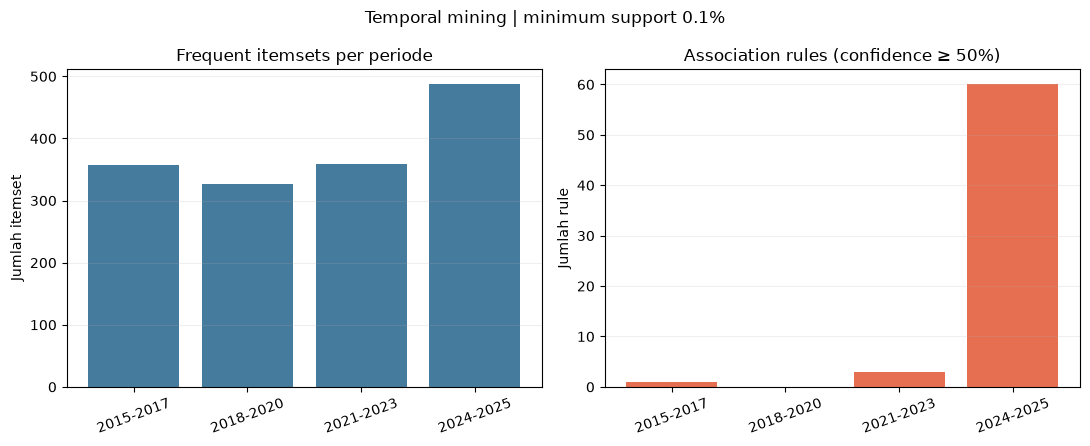

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(summary_df["period"], summary_df["frequent_itemsets"], color="#457b9d")
axes[0].set_title("Frequent itemsets per periode")
axes[0].set_ylabel("Jumlah itemset")
axes[1].bar(summary_df["period"], summary_df["association_rules"], color="#e76f51")
axes[1].set_title(f"Association rules (confidence ≥ {MIN_CONFIDENCE:.0%})")
axes[1].set_ylabel("Jumlah rule")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.2)
fig.suptitle(f"Temporal mining | minimum support {MIN_SUPPORT:.1%}")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "bagianE_pattern_counts.png", dpi=160, bbox_inches="tight")
plt.show()

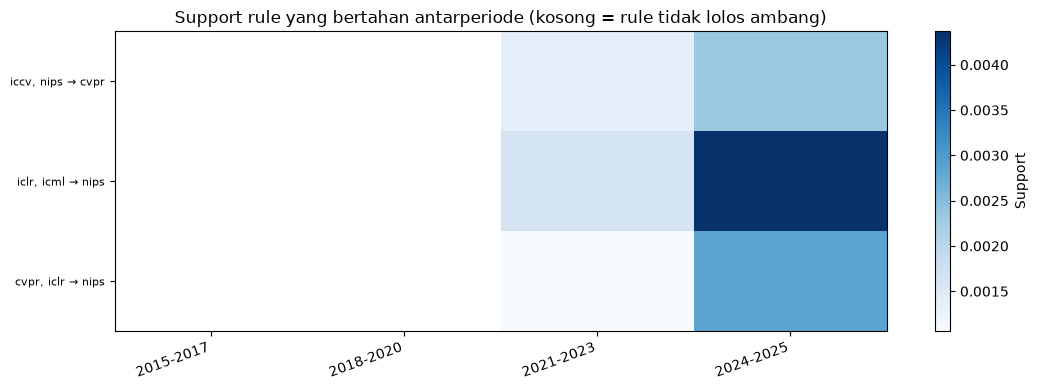

In [5]:
fig, ax = plt.subplots(figsize=(11, max(4, 0.48 * min(10, len(persistent_df)))))
if persistent_df.empty:
    ax.text(0.5, 0.5, "Tidak ada rule yang bertahan pada minimal dua periode",
            ha="center", va="center")
    ax.set_axis_off()
else:
    selected = persistent_df.head(10)
    matrix = selected[support_columns].to_numpy(dtype=float)
    image = ax.imshow(np.ma.masked_invalid(matrix), aspect="auto", cmap="Blues")
    labels = [
        f"{row.antecedents} → {row.consequents}"[:90]
        for row in selected.itertuples(index=False)
    ]
    ax.set_yticks(range(len(labels)), labels=labels, fontsize=8)
    ax.set_xticks(range(len(PERIOD_NAMES)), labels=PERIOD_NAMES, rotation=20, ha="right")
    ax.set_title("Support rule yang bertahan antarperiode (kosong = rule tidak lolos ambang)")
    fig.colorbar(image, ax=ax, label="Support")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "bagianE_persistent_rule_support.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. Interpretasi dan batasan

- **Frequent itemset** menunjukkan venue yang muncul bersama pada transaksi author-tahun. **Support** adalah proporsi transaksi author-tahun yang memuat pola tersebut; **confidence** adalah proporsi transaksi antecedent yang juga memuat consequent; **lift** membandingkan confidence dengan support consequent. Lift di atas 1 mengindikasikan kemunculan bersama lebih sering daripada baseline independen.
- Rule yang muncul berulang dengan lift di atas 1 merupakan kandidat pola yang bertahan. Rule yang hanya lolos ambang pada satu periode adalah kandidat pola yang berubah/khusus periode; cek support dan ukuran absolutnya sebelum menafsirkan.
Pada dataset dan ambang saat ini (support 0,1%, confidence 50%), jumlah rule per periode adalah 1, 0, 3, dan 60. Tidak ada rule berarah yang lolos ambang di keempat periode; tiga pola yang berulang muncul pada 2021–2023 dan 2024–2025: `ICCV + NIPS → CVPR`, `ICLR + ICML → NIPS`, dan `CVPR + ICLR → NIPS`. Pada 2024–2025, contoh lift tertinggi adalah `EMNLP (Findings) + NAACL-HLT + NIPS → ACL` (support 0,1016%, confidence 72,43%, lift 28,97). Ini memberi indikasi asosiasi lintas venue pada area AI/NLP dan computer vision, tetapi pola spesifik periode maupun kenaikan jumlah rule dapat dipengaruhi cakupan dan panjang periode.
- Perbandingan ini mengukur perubahan asosiasi publikasi, bukan perpindahan penulis antar-konferensi atau hubungan sebab-akibat. Authors dapat berulang di beberapa transaksi tahun yang berbeda.
- Minimum support relatif dan confidence dibuat sama di semua periode. Meski begitu, periode memiliki panjang berbeda (periode terakhir hanya dua tahun), cakupan data/venue dapat berubah, dan rule langka dapat sensitif terhadap ambang; interpretasi perlu mempertimbangkan jumlah transaksi per periode pada tabel ringkasan.